# 02. 무작위 SCM으로 표 데이터셋 만들기 — TabPFN prior의 축소판

[`01_scm_primer`](01_scm_primer.ipynb)에서는 SCM을 손으로 적고, 위상 순서대로 샘플링하고, 개입까지 해 봤습니다. TabPFN의 prior는 SCM을 손으로 적지 않고 SCM 자체를 무작위로 뽑습니다. 이 노트북은 그 절차를 작게 줄여 직접 따라가고, 그렇게 만든 표가 PFN에 어떻게 들어가는지 봅니다.

다루는 흐름:

1. 무작위 SCM을 뽑는 절차 — 논문 부록 C.1
2. 작은 예로 먼저 보기 — 모든 노드를 계산하고 열 몇 개만 남기기
3. 무작위 SCM 샘플러로 데이터셋 뽑기
4. PFN에는 이 표가 어떻게 들어가나
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/02_tabpfn/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# rng = random number generator(난수 생성기). 노이즈 등 모든 무작위 값을 여기서 뽑는다.
# 시드 0으로 고정해 실행할 때마다 같은 난수가 나오게 한다.
rng = np.random.default_rng(0)
# 앞 노트북(1~5절)이 쓴 난수 128,000개를 건너뛴다. 두 노트북이 하나였을 때와 같은 예제가 나온다.
rng.standard_normal(128_000);

In [3]:
# 앞 노트북(01_scm_primer)에서 만든 도우미: DAG 그림, 위상 순서, SCM 샘플링
def draw_dag(ax, edges, pos, colors=None, node_size=900, labels=True, title=None):
    # edges: [(원인, 결과), ...], pos: {노드: (x, y)}
    colors = colors or {}
    shrink = np.sqrt(node_size) / 2
    for u, v in edges:
        ax.annotate(
            "",
            xy=pos[v],
            xytext=pos[u],
            arrowprops=dict(arrowstyle="-|>", color="gray", lw=1, shrinkA=shrink, shrinkB=shrink),
        )
    for node, (x, y) in pos.items():
        ax.scatter(x, y, s=node_size, color=colors.get(node, "white"), edgecolor="black", zorder=3)
        if labels:
            ax.text(x, y, node, ha="center", va="center", fontsize=9, zorder=4)
    ax.set_title(title)
    ax.axis("off")
    ax.margins(0.15)


def topological_order(parents):
    # 부모가 모두 정해진 노드부터 차례로 꺼낸다 (DAG라서 항상 끝난다).
    order, done = [], set()
    while len(order) < len(parents):
        for node, pa in parents.items():
            if node not in done and all(p in done for p in pa):
                order.append(node)
                done.add(node)
    return order


def sample_scm(parents, equations, n, rng, do=None):
    # parents: {노드: [부모, ...]}, equations: {노드: f(부모 값 dict, 노이즈)}
    # do: {노드: 값} — 해당 노드의 식을 상수로 바꿔 끼운다 (앞 노트북 5절).
    do = do or {}
    values = {}
    for node in topological_order(parents):
        if node in do:
            values[node] = np.full(n, float(do[node]))  # 개입: 식 대신 상수
            continue
        # 1) 부모 값을 모은다. 위상 순서로 돌기 때문에 부모는 이미 values에 있다.
        parent_values = {p: values[p] for p in parents[node]}
        # 2) 이 노드의 노이즈 ε를 뽑는다.
        noise = rng.standard_normal(n)
        # 3) 구조 방정식 f에 넣어 값을 계산한다: z = f(부모 값, ε)
        f = equations[node]
        values[node] = f(parent_values, noise)
    return values

## 1. 무작위 SCM을 뽑는 절차 — 부록 C.1

지금까지는 SCM을 손으로 적었습니다. TabPFN의 prior는 SCM 자체를 무작위로 뽑습니다. 논문 부록 C.1의 절차를 줄이면 다음과 같습니다.

1. 층 수 $l$과 층당 노드 수 $h$를 뽑아 MLP 모양의 그래프를 만듭니다.
2. 가중치를 뽑고, 간선 일부를 무작위로 지워(dropout) 다양한 DAG를 만듭니다.
3. 각 노드 값은 $z = a(W z_{\text{prev}}) + \epsilon$으로 계산합니다. 활성화 함수 $a$는 {tanh, LeakyReLU, ELU, identity} 중 하나를 고릅니다.
4. 전체 노드 중 일부를 feature $x$로, 하나를 target $y$로 고릅니다. 나머지는 관측되지 않는 노드 $z$입니다.
5. 연속값 target을 무작위 경계로 잘라 클래스로 바꾸고, 클래스 번호를 섞습니다(4.5절).

feature와 target은 그래프 아무 위치에서나 뽑히므로, feature가 target의 원인일 수도, 결과일 수도, target과 무관할 수도 있습니다. 또 4.2절의 단순성(Occam's razor)에 따라 층과 노드가 적은 작은 그래프가 더 자주 뽑히도록 분포를 잡습니다.

아래 구현은 이 절차를 따르되 하이퍼파라미터 분포는 단순하게 바꿨습니다. 논문의 실제 값(부록 E.4)은 [TabPFN 논문 walkthrough의 prior 편](05_tabpfn_paper_prior.ipynb)에서 다룹니다.

## 2. 작은 예로 먼저 보기

무작위로 뽑기 전에, 층 3개 × 노드 2개짜리 작은 SCM을 손으로 만들어 4번 단계를 따라가 봅니다. 4번 단계는 두 단계로 나뉩니다.

1. 그래프의 **모든 노드** 값을 계산해 큰 표를 만듭니다. 노드 하나가 열 하나입니다.
2. 그 표에서 **열 몇 개만** 남깁니다. 남긴 열이 feature $x$와 target $y$이고, 버린 열이 관측되지 않는 노드 $z$입니다.

어떤 열을 남길지는 층과 상관없이 정합니다. 그래서 같은 층 안에서도 어떤 노드는 남고 어떤 노드는 버려집니다. 아래 예에서는 설명하기 쉽게 직접 골랐지만, TabPFN은 무작위로 고릅니다.

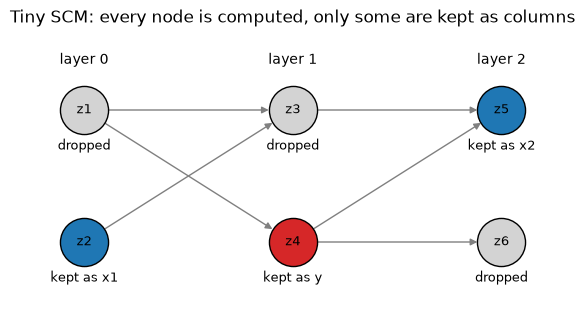

In [4]:
tiny_parents = {
    # layer 0: 노이즈만으로 정해지는 원인 노드
    "z1": [],
    "z2": [],
    # layer 1
    "z3": ["z1", "z2"],
    "z4": ["z1"],
    # layer 2
    "z5": ["z3", "z4"],
    "z6": ["z4"],
}
tiny_equations = {
    "z1": lambda pa, e: e,
    "z2": lambda pa, e: e,
    "z3": lambda pa, e: np.tanh(1.5 * pa["z1"] - pa["z2"]) + 0.1 * e,
    "z4": lambda pa, e: np.tanh(-2 * pa["z1"]) + 0.1 * e,
    "z5": lambda pa, e: np.tanh(pa["z3"] + pa["z4"]) + 0.1 * e,
    "z6": lambda pa, e: np.tanh(1.2 * pa["z4"]) + 0.1 * e,
}
# 표에 남길 열: 노드 이름 -> 데이터셋에서의 이름. 나머지(z1, z3, z6)는 버린다.
kept = {"z2": "x1", "z4": "y", "z5": "x2"}

pos = {"z1": (0, 0), "z2": (0, -1), "z3": (1, 0), "z4": (1, -1), "z5": (2, 0), "z6": (2, -1)}
colors = {node: "lightgray" for node in pos}
for node, name in kept.items():
    colors[node] = "C3" if name == "y" else "C0"
edges = [(p, node) for node, pa in tiny_parents.items() for p in pa]

fig, ax = plt.subplots(figsize=(7, 3.6))
draw_dag(ax, edges, pos, colors, node_size=1200)
for node, (x, y) in pos.items():
    ax.text(
        x, y - 0.3, f"kept as {kept[node]}" if node in kept else "dropped", ha="center", fontsize=9
    )
for k in range(3):
    ax.text(k, 0.35, f"layer {k}", ha="center", fontsize=10)
ax.set_ylim(-1.5, 0.6)
ax.set_title("Tiny SCM: every node is computed, only some are kept as columns")
plt.show()

**1단계: 모든 노드를 계산합니다.** 앞 노트북 3절의 `sample_scm`(위에 다시 적어 둔 것)을 그대로 써서 샘플 5개를 뽑으면 노드 6개가 모두 열로 있는 표가 나옵니다.

In [5]:
all_nodes = pd.DataFrame(sample_scm(tiny_parents, tiny_equations, 5, rng)).round(2)
all_nodes

,z1,z2,z3,z4,z5,z6
0,1.66,-1.60,0.88,-0.84,0.15,-0.66
1,0.59,-1.62,1.15,-0.93,0.23,-0.95
2,0.18,1.48,-0.79,-0.46,-0.88,-0.45
3,-0.92,0.42,-0.84,0.74,-0.02,0.81
4,1.35,0.30,0.81,-1.11,-0.28,-1.02


**2단계: 열 몇 개만 남깁니다.** 아래 표가 PFN이 실제로 받는 데이터셋입니다.

In [6]:
dataset = all_nodes[list(kept)].rename(columns=kept)
dataset

,x1,y,x2
0,-1.60,-0.84,0.15
1,-1.62,-0.93,0.23
2,1.48,-0.46,-0.88
3,0.42,0.74,-0.02
4,0.30,-1.11,-0.28


z1, z3, z6 열은 버렸습니다. z1은 feature인 z2와 같은 layer 0에 있고, z3는 target인 z4와 같은 layer 1에 있습니다. 둘 다 표에 남지 않았을 뿐 값은 1단계에서 계산되었고 다른 노드에 영향을 줬습니다. 예를 들어 target y(z4)는 버려진 z1으로만 정해지므로, 데이터셋만 보는 사람에게 z1은 "보이지 않는 원인"입니다. 앞 노트북 1절에 비유하면, 표에 아이스크림과 선크림 판매량 열만 있고 기온 열이 없을 때 기온이 z1 같은 노드입니다.

남긴 열과 target의 관계도 그래프가 정합니다. x2(z5)는 y(z4)의 결과이므로 y를 예측하는 데 도움이 됩니다. 반면 x1(z2)에서 y로 가는 경로는 없고, 둘이 공유하는 원인도 없어서 x1은 y와 무관합니다.

## 3. 무작위 SCM 샘플러로 데이터셋 뽑기

이제 층 수, 노드 수, 가중치, 지울 간선, 활성화 함수, feature·target 노드를 모두 무작위로 뽑습니다. `sample_random_scm`이 1절의 1~4단계로 SCM 하나를 뽑고, `sample_dataset`이 그 SCM으로 행을 만든 뒤 5단계처럼 target을 클래스로 바꿉니다.

In [7]:
ACTIVATIONS = {
    "tanh": np.tanh,
    "leaky_relu": lambda z: np.where(z > 0, z, 0.01 * z),
    "elu": lambda z: np.where(z > 0, z, np.expm1(np.minimum(z, 0))),
    "identity": lambda z: z,
}


def sample_random_scm(n_features, rng):
    # 층 수와 노드 수는 작은 값이 더 자주 나오도록 뽑는다 (단순성).
    n_layers = int(rng.integers(2, 5))
    hidden = int(np.exp(rng.uniform(np.log(4), np.log(16))))
    hidden = max(hidden, -(-(n_features + 1) // (n_layers + 1)))  # 노드가 feature + target보다 많게
    w_std = np.exp(rng.uniform(np.log(0.3), np.log(3)))
    p_drop = rng.uniform(0, 0.8)
    weights = [rng.normal(0, w_std, (hidden, hidden)) for _ in range(n_layers)]
    masks = [rng.random((hidden, hidden)) > p_drop for _ in range(n_layers)]  # False = 지운 간선
    n_nodes = (n_layers + 1) * hidden
    nodes = rng.choice(n_nodes, n_features + 1, replace=False)
    return {
        "n_layers": n_layers,
        "hidden": hidden,
        "activation": str(rng.choice(list(ACTIVATIONS))),
        "noise_std": np.exp(rng.uniform(np.log(1e-3), np.log(0.3))),
        "weights": [w * m for w, m in zip(weights, masks, strict=True)],
        "masks": masks,
        "feature_nodes": nodes[:-1],
        "target_node": nodes[-1],
    }


def sample_dataset(scm, n_samples, max_classes, rng):
    act = ACTIVATIONS[scm["activation"]]
    z = rng.standard_normal((n_samples, scm["hidden"]))  # 첫 층: 원인 노드 (노이즈만으로 정해진다)
    layers = [z]
    for w in scm["weights"]:
        z = act(z @ w) + scm["noise_std"] * rng.standard_normal(z.shape)
        layers.append(z)
    all_nodes = np.concatenate(layers, axis=1)

    x = all_nodes[:, scm["feature_nodes"]]
    x = (x - x.mean(0)) / (x.std(0) + 1e-8)  # 표준화 (부록 C.2.1)
    y_cont = all_nodes[:, scm["target_node"]]

    # 4.5절: 연속 target에서 경계를 뽑아 구간 번호를 클래스로 쓰고, 번호를 섞는다.
    n_classes = int(rng.integers(2, max_classes + 1))
    bounds = np.sort(rng.choice(y_cont, n_classes - 1, replace=False))
    y = rng.permutation(n_classes)[np.searchsorted(bounds, y_cont)]
    return x, y

이제 `sample_random_scm`으로 뽑은 SCM을 같은 방식으로 그려 봅니다. 위의 작은 예를 층과 노드 수만 키운 것입니다. 열(층)은 계산 순서이고, 색은 그 노드를 표의 열로 남겼는지를 나타냅니다.

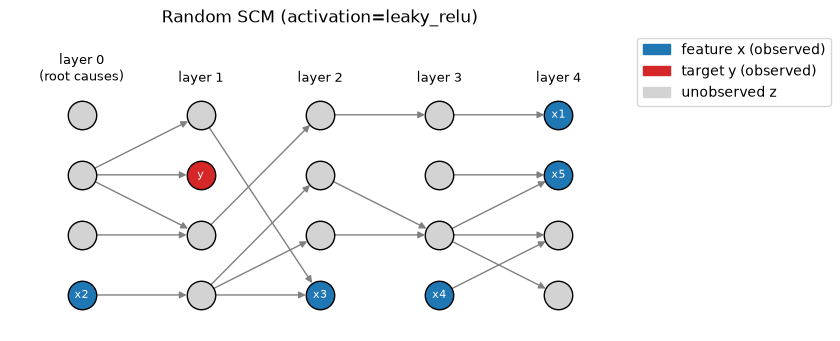

In [8]:
from matplotlib.patches import Patch

scm = sample_random_scm(n_features=5, rng=rng)
h = scm["hidden"]
# 노드 번호 k * h + j = k번째 층의 j번째 노드
pos = {k * h + j: (k, -j) for k in range(scm["n_layers"] + 1) for j in range(h)}

edges = []
for k, mask in enumerate(scm["masks"]):  # mask[i, j]: k층 i번 → k+1층 j번 간선이 남았는가
    for i, j in zip(*np.nonzero(mask), strict=True):
        edges.append((k * h + i, (k + 1) * h + j))

colors = {node: "lightgray" for node in pos}  # 기본은 관측되지 않는 노드 z
names = {}
for i, node in enumerate(scm["feature_nodes"]):
    colors[int(node)] = "C0"
    names[int(node)] = f"x{i + 1}"
colors[int(scm["target_node"])] = "C3"
names[int(scm["target_node"])] = "y"

fig, ax = plt.subplots(figsize=(8, 0.6 * h + 1.5))
draw_dag(ax, edges, pos, colors, node_size=420, labels=False)
for node, name in names.items():
    ax.text(*pos[node], name, ha="center", va="center", fontsize=8, color="white", zorder=4)
for k in range(scm["n_layers"] + 1):
    label = "layer 0\n(root causes)" if k == 0 else f"layer {k}"
    ax.text(k, 0.5, label, ha="center", va="bottom", fontsize=9)
ax.set_ylim(-h + 0.4, 1.4)
ax.set_title(f"Random SCM (activation={scm['activation']})")
ax.legend(
    handles=[
        Patch(color="C0", label="feature x (observed)"),
        Patch(color="C3", label="target y (observed)"),
        Patch(color="lightgray", label="unobserved z"),
    ],
    loc="upper left",
    bbox_to_anchor=(1.0, 1.0),
)
plt.show()

feature가 target보다 왼쪽 층에 있으면 target의 원인 쪽이고, 오른쪽 층에 있으면 target의 결과 쪽입니다. 같은 층에 있으면 서로 직접 이어져 있지는 않지만, 앞 층의 공통 원인을 공유해서 상관될 수 있습니다(앞 노트북 1절에서 기온을 공유하는 아이스크림과 선크림처럼). 이어진 경로도 공통 원인도 없으면 target과 무관한 feature가 됩니다. 현실의 표 데이터에도 target의 원인인 열, 결과인 열, 상관없는 열이 섞여 있으므로, prior도 이런 경우를 모두 만들어 냅니다. 논문 Figure 2가 보여 주는 것도 이 구조입니다(*"Inputs x are mapped to the output y through unobserved nodes z"*).

같은 방식으로 feature 2개짜리 데이터셋을 200개 뽑습니다. 무작위로 고른 feature 2개는 target과 거의 무관한 경우가 많습니다. target이 관측되지 않는 다른 노드에 주로 좌우되기 때문입니다. 데이터셋마다 feature로 클래스를 얼마나 맞힐 수 있는지를 "kNN 교차검증 정확도 − 가장 많은 클래스의 비율"(gain)로 재 봅니다.

In [9]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

datasets = []
for _ in range(200):
    scm = sample_random_scm(n_features=2, rng=rng)
    x, y = sample_dataset(scm, n_samples=300, max_classes=4, rng=rng)
    acc = cross_val_score(KNeighborsClassifier(15), x, y, cv=KFold(3, shuffle=True, random_state=0))
    gain = acc.mean() - np.bincount(y).max() / len(y)
    datasets.append((scm, x, y, gain))

gains = np.array([d[3] for d in datasets])
print(f"gain > 0.15 (feature로 클래스를 꽤 맞힘): {np.mean(gains > 0.15):.0%}")
print(f"gain < 0.05 (거의 못 맞힘):              {np.mean(gains < 0.05):.0%}")

gain > 0.15 (feature로 클래스를 꽤 맞힘): 16%
gain < 0.05 (거의 못 맞힘):              68%


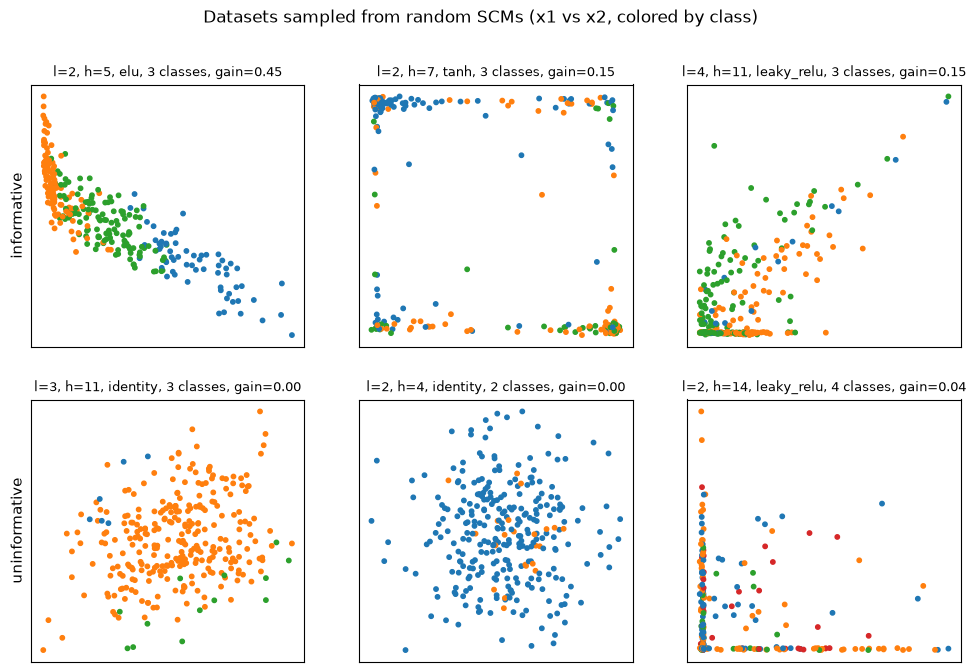

In [10]:
informative = [d for d in datasets if d[3] > 0.15][:3]
uninformative = [d for d in datasets if d[3] < 0.05][:3]

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, (scm, x, y, gain) in zip(axes.flat, informative + uninformative, strict=True):
    ax.scatter(x[:, 0], x[:, 1], c=y, cmap="tab10", vmin=0, vmax=9, s=10)
    ax.set_title(
        f"l={scm['n_layers']}, h={scm['hidden']}, {scm['activation']}, "
        f"{y.max() + 1} classes, gain={gain:.2f}",
        fontsize=9,
    )
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 0].set_ylabel("informative", fontsize=11)
axes[1, 0].set_ylabel("uninformative", fontsize=11)
fig.suptitle("Datasets sampled from random SCMs (x1 vs x2, colored by class)")
plt.show()

윗줄은 feature로 클래스를 잘 맞힐 수 있는 데이터셋, 아랫줄은 거의 못 맞히는 데이터셋입니다. 결정 경계의 모양, 클래스 수, 클래스 비율이 데이터셋마다 다릅니다. 현실에도 feature가 target을 거의 설명하지 못하는 데이터셋이 있으므로, 이런 데이터셋도 prior에 들어가는 것이 자연스럽습니다. 실제 TabPFN은 feature를 훨씬 많이(최대 100개) 뽑고, 인접한 노드를 묶어 뽑는 방식(blockwise sampling, 부록 C.2.2)으로 feature끼리의 상관도 현실 데이터와 비슷하게 만듭니다.

## 4. PFN에는 이 표가 어떻게 들어가나

이렇게 만든 표 하나가 PFN의 학습 예제 하나입니다. 표의 행을 둘로 나눠, 학습 행은 y까지 보여 주고 테스트 행은 y를 가린 채 넣습니다. 위에서 만든 데이터셋 하나로 보면 다음과 같습니다.

In [11]:
_, x, y, _ = informative[0]
table = pd.DataFrame({"x1": x[:5, 0].round(2), "x2": x[:5, 1].round(2), "y": y[:5].astype(object)})
table.loc[3:, "y"] = "?"  # 테스트 행은 y를 가린다
table.insert(0, "역할", ["학습 행 (context)"] * 3 + ["테스트 행 (query)"] * 2)
table

,역할,x1,x2,y
0,학습 행 (context),-1.08,1.86,1
1,학습 행 (context),0.40,-0.39,2
2,학습 행 (context),3.00,-2.36,0
3,테스트 행 (query),-1.01,0.35,?
4,테스트 행 (query),0.38,-0.43,?


- **입력**: y까지 채워진 학습 행 전부와, y가 비어 있는 테스트 행의 x를 한꺼번에 Transformer에 넣습니다.
- **출력**: 각 `?` 자리마다 y의 분포, 즉 클래스별 확률을 냅니다(예: 클래스 0일 확률 0.2, 클래스 1일 확률 0.8). 값 하나가 아니라 분포라는 점이 PPD $p(y \mid x, D)$를 근사한다는 뜻입니다.
- **`?`가 여러 개일 때**: 테스트 행은 학습 행만 참고하고 서로는 참고하지 않습니다(attention mask, [`01_pfn/03`](../01_pfn/03_pfn_implementation_details.ipynb) 7절). 그래서 `?`를 몇 개 넣든 각자 따로 예측됩니다.

학습할 때와 실제로 쓸 때의 차이는 `?`의 정답을 아느냐뿐입니다.

- **학습할 때(prior-fitting)**: 표를 SCM으로 직접 만들었으므로 `?`의 정답을 압니다. 예측한 분포가 정답에 준 확률로 NLL을 계산해 Transformer 가중치를 업데이트합니다. TabPFN은 이렇게 데이터셋 약 900만 개(512개짜리 batch × 18,000 step)로 학습합니다.
- **실제로 쓸 때(추론)**: 내 데이터의 학습 행과 테스트 행을 넣으면 forward pass 한 번으로 `?`의 분포가 나옵니다. 가중치는 바뀌지 않습니다.

그래서 TabPFN은 새 데이터셋을 "학습"한다기보다, 학습 행을 문맥으로 읽고 빈칸을 채우는 쪽에 가깝습니다.

## 5. 정리

| 개념 | 이 노트북 | TabPFN에서 |
|---|---|---|
| 무작위 SCM | `sample_random_scm`, `sample_dataset` | SCM prior (BNN prior와 섞어 씀) |
| 관측되지 않는 노드 | 모든 노드를 계산한 뒤 열 몇 개만 남긴다 | feature가 target의 원인·결과·무관한 열로 섞인다 |
| PFN 입력 | 학습 행 + y를 `?`로 가린 테스트 행 | `?` 자리의 클래스 분포를 예측 |

다음 노트북 [`03_bnn_primer`](03_bnn_primer.ipynb)에서는 TabPFN prior의 나머지 절반인 BNN prior를 봅니다.